<a href="https://colab.research.google.com/github/dgromann/cl_intro_ws2026/blob/main/tutorials/Tutorial4_model_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 4: Word Embeddings and PyTorch
This is the third tutorial with practical exercises for the lecture Introduction to Computational Linguistics in the Winter Semester 2026. Hands-on exercises are marked with 👋 ⚒ and questions are marked with ❓. Remember to first **store this notebook** in your Drive or GitHub.

---

## **Part 1: Already Trained Word Embeddings**

For faster processing, we are going to use GloVe embeddings, a close relative to word2vec from the lecture, with a dimensionality of 50 instead of 300 and a closer relation to count-based approaches. GloVe first counts how often every pair co-occurs in the whole corpus, then fits vectors to those counts. The results of word2vec and GloVe look similar. This is the original GloVe paper:


*   Pennington, J., Socher, R., & Manning, C. D. (2014). [Glove: Global vectors for word representation](https://aclanthology.org/D14-1162.pdf). In: Proceedings of the 2014 conference on empirical methods in natural language processing (EMNLP) (pp. 1532-1543).


There are several ways to train and use trained embeddings:
- `gensim`: simplest and straightforward implementation of `word2vec` and `GloVe`
- Training based on deep learning packages e.g., `tensorflow` and `torch`
- `spacy`: comes with a pre-trained embeddings models, using `GloVe`

Let us start with installing the gensim environment to handle different types of word embeddings and with some basic experiments.


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 65.7 MB/s  0:00:00


With the API of gensim we can load different already trained embeddings into our notebook environment. A list of available embedding models can be found [here](https://github.com/piskvorky/gensim-data).

In [ ]:
import gensim.downloader as api
from gensim.models import Word2Vec

glove_embeddings = api.load("glove-wiki-gigaword-50")

[==================================================] 100.0% 66.0/66.0MB downloaded


We can check the length of the entire vocabulary in the embedding model and access individual embeddings.

In [ ]:
print(f"Length of the vocabulary {len(glove_embeddings.key_to_index)}")
print(f"Embedding for the word good: \n {glove_embeddings["good"]}")

Length of the vocabulary 400000
Embedding for the word good: 
 [-3.5586e-01  5.2130e-01 -6.1070e-01 -3.0131e-01  9.4862e-01 -3.1539e-01
 -5.9831e-01  1.2188e-01 -3.1943e-02  5.5695e-01 -1.0621e-01  6.3399e-01
 -4.7340e-01 -7.5895e-02  3.8247e-01  8.1569e-02  8.2214e-01  2.2220e-01
 -8.3764e-03 -7.6620e-01 -5.6253e-01  6.1759e-01  2.0292e-01 -4.8598e-02
  8.7815e-01 -1.6549e+00 -7.7418e-01  1.5435e-01  9.4823e-01 -3.9520e-01
  3.7302e+00  8.2855e-01 -1.4104e-01  1.6395e-02  2.1115e-01 -3.6085e-02
 -1.5587e-01  8.6583e-01  2.6309e-01 -7.1015e-01 -3.6770e-02  1.8282e-03
 -1.7704e-01  2.7032e-01  1.1026e-01  1.4133e-01 -5.7322e-02  2.7207e-01
  3.1305e-01  9.2771e-01]


👋 ⚒ Exercise 1: Print how many dimensions a single vector in the GloVe embeddings has.

In [ ]:
# Your code here
print(len(glove_embeddings["good"]))

50


The method `most_similar` allows us to explore the `topn`words that are most closely related to the word we input in vector space.

In [ ]:
glove_embeddings.most_similar("coffee", topn=8)

[('drink', 0.818743884563446),
 ('drinks', 0.8176289796829224),
 ('wine', 0.8141362071037292),
 ('tea', 0.8079647421836853),
 ('beer', 0.8042463660240173),
 ('food', 0.7853199243545532),
 ('sugar', 0.7774224281311035),
 ('corn', 0.7606631517410278)]

👋 ⚒ Exercise 2: Query the closest neighbors of three words of your own choice using `most_similar` and return only the top 5 results. Were any of the results surprising?  

In [ ]:
# Your examples and code here
glove_embeddings.most_similar("child", topn=5)
glove_embeddings.most_similar("stalin", topn=5)
glove_embeddings.most_similar("morocco", topn=5)

[('tunisia', 0.8987523913383484),
 ('algeria', 0.8382717967033386),
 ('egypt', 0.8373337388038635),
 ('mauritania', 0.7876071333885193),
 ('bahrain', 0.7863556742668152)]

We can also check the actual numbers that were learned for these words, which in this case are represented as numpy arrays.

In [ ]:
coffee = glove_embeddings["coffee"]
print(f"King as numpy size: {coffee.size}")
print(f"King as numpy array: {coffee}")
print(f"King really is a : {type(coffee)}")

King as numpy size: 50
King as numpy array: [-0.54015  -0.29931  -0.67591   0.15784   0.90241  -0.89567  -1.1267
 -0.69013   0.7116    0.71231   0.11031  -0.37268   0.93846  -0.42899
  1.0807    0.43785  -0.38785   0.65528   0.34501  -1.3793    1.114
 -0.20227   0.53612   0.67394  -0.52717  -0.30703  -0.14833   0.78579
  0.84364   0.56468   2.1954   -0.097544 -0.41744   1.0296    0.083024
 -0.1552   -1.1257    0.74416   1.1534    0.24415   0.057113  0.63826
 -0.35989  -0.031659  0.88827   0.78731  -0.47028  -0.69737   0.12029
 -0.41486 ]
King really is a : <class 'numpy.ndarray'>


👋 ⚒ Exercise 3: Similarity in this case means cosine similarity, which is the dot product of vectors u and v divided by the product of their magnitude (lengths). This division serves the purpose to strip away the magnitude and focus on the angle between the two vectors alone (=their distance). In numpy, there is the function `np.dot()`for the dot product of two 1D arrays and in the linear algebra (linalg) module a function for magnitude `np.linalg.norm()` that takes a single 1D array as input. Implement the `numpy_cosine` function.

$$ \cos(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|} = \frac{\sum_{i=1}^{n} u_i v_i}{\sqrt{\sum_{i=1}^{n} u_i^2} \sqrt{\sum_{i=1}^{n} v_i^2}}$$



In [ ]:
import numpy as np

def numpy_cosine(u, v):
  #Your code here
  return np.dot(u,v)/ (np.linalg.norm(u) * np.linalg.norm(v))

print(numpy_cosine(glove_embeddings["king"], glove_embeddings["queen"]))
print(numpy_cosine(glove_embeddings["king"], glove_embeddings["banana"]))
print(glove_embeddings.similarity("king", "queen")) # this should match your result

0.7839044
0.22074082
0.7839043


This function can also be used for analogies, as the famous king is to queen as man is to woman analogy.

In [ ]:
glove_embeddings.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
glove_embeddings.most_similar(positive=["vienna", "france"], negative=["paris"], topn=3)

[('germany', 0.8144438862800598),
 ('netherlands', 0.8010364770889282),
 ('austria', 0.7989991903305054)]

We can use matplotlib to visualize the proximity of words in vector space.

In [ ]:
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt

def display_pca_scatterplot(model, words):

    word_vectors = np.array([model[w] for w in words])

    twodim = PCA().fit_transform(word_vectors)[:,:2]

    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

display_pca_scatterplot(glove_embeddings,
                        ['coffee', 'tea', 'beer', 'wine', 'water',
                         'hamburger', 'pizza',  'sushi', 'meatballs',
                         'dog', 'horse', 'cat', 'monkey', 'parrot', 'lizard',
                         'france', 'germany', 'hungary',
                         'school', 'college', 'university', 'institute'])

NameError: name 'np' is not defined

---

## **Part 2: PyTorch Basics**

To write code for neural networks from scratch instead of using already existing models and libraries, there are mainly two machine learning frameworks:

*   TensorFlow
*   Torch

Since these are high level core libraries in other programming languages, e.g. Torch is originally written in [Lua](https://www.lua.org/about.html), it is easier to use frameworks that build on top of them, adding usability and documentation. We are going to focus on Torch and its Python version [PyTorch](https://pytorch.org/), equally called torch in the Python libraries.

The most basic and important concept in PyTorch is that of a **Tensor**. [What is a tensor?](https://en.wikipedia.org/wiki/Tensor). A tensor is a grid of numbers: a list (1D), a table (2D), and so on. It is similar a Python list that is fast, supports maths on all elements at once, and can compute gradients.

While very similar to numpy arrays, tensors tend to speed up computations and offer more flexibility.

In [ ]:
import torch
import numpy

# Seed for random number generator to ensure reproducibility of
# random initializations
torch.manual_seed(1)

#Difference between tensor and numpy array
a = torch.ones(5)
print(f"Tensor: {a}")
print(f"Type of a (py)torch tensor: {type(a)}")
print(f"Numpy array: {a.numpy()}")
print(f"Type of a numpy tensor: {type(a.numpy())}")

Tensor: tensor([1., 1., 1., 1., 1.])
Type of a (py)torch tensor: <class 'torch.Tensor'>
Numpy array: [1. 1. 1. 1. 1.]
Type of a numpy tensor: <class 'numpy.ndarray'>


There are different ways to initialize a tensor exemplified in the following code cell.

In [ ]:
# This creates a randomly initialized 5 x 3 matrix
random_tensor = torch.rand(5,3)
print(f"Randomly initialized tensor: \n {random_tensor}")
print(f"The shape of the matrix is its dimensions (here 5x3): {random_tensor.shape}")

# This creates a 5 x 3 matrix filled with zeros and of dtype long
# There are eight datatypes in tensor, this one is a datatype of 64-bit integer (signed)
# Here are the others: https://pytorch.org/docs/stable/tensors.html
zeros = torch.zeros(4,3, dtype=torch.long)
print(f"Tensor initialized with zeros: \n {zeros}")

# Directly initialize a tensor with data
data = torch.tensor([[5.5, 3], [1, 2]])
print(f"Tensor initilialized with data: \n {data}")

Randomly initialized tensor: 
 tensor([[0.6397, 0.9743, 0.8300],
        [0.0444, 0.0246, 0.2588],
        [0.9391, 0.4167, 0.7140],
        [0.2676, 0.9906, 0.2885],
        [0.8750, 0.5059, 0.2366]])
The shape of the matrix is its dimensions (here 5x3): torch.Size([5, 3])
Tensor initialized with zeros: 
 tensor([[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]])
Tensor initilialized with data: 
 tensor([[5.5000, 3.0000],
        [1.0000, 2.0000]])


A randomly initiatilzed tensor with only ones (`new_ones`), zeros (`torch.zeros`) or truly random (`torch.rand`), can be re-initialized with `torch.rand_like`. The difference is that with the other functions you need to pass the specific dimensions, whereas with `torch.rand_like` the tensor inherits these properties from the given tensor.    

In [ ]:
ones_only = random_tensor.new_ones(5, 3, dtype=torch.float)
print(f"Randomly initialized tensor with ones only: \n {ones_only}")
print(f"And this is its size: {ones_only.size()}")

redefined_too = torch.rand_like(ones_only)
print(f"Redefining the ones only tensor: \n {redefined_too}")
print(f"And this is its size: {redefined_too.size()}")

Randomly initialized tensor with ones only: 
 tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
And this is its size: torch.Size([5, 3])
Redefining the ones only tensor: 
 tensor([[0.7570, 0.2346, 0.6471],
        [0.3556, 0.4452, 0.0193],
        [0.2616, 0.7713, 0.3785],
        [0.9980, 0.9008, 0.4766],
        [0.1663, 0.8045, 0.6552]])
And this is its size: torch.Size([5, 3])


Tensors in torch also support basic operations:

In [ ]:
a = torch.tensor([1., 2., 3.])
b = torch.tensor([4., 5., 6.])
print(a + b)
print(a * b)
print((a * b).sum())    # dot product = multiply, then sum
print(torch.dot(a, b))  # there is also a built in function for the dot product of two 1D tensors
print(a.norm())         # to get the magnitude (lengths) of a vector
print(a.shape)

tensor([5., 7., 9.])
tensor([ 4., 10., 18.])
tensor(32.)
tensor(32.)
tensor(3.7417)
torch.Size([3])


Tensors can also be indexed and the important dot product can be easily calculated:

In [ ]:
c = torch.rand(5,3)
print(f"Entire tensor c: \n {c}")
print(f"c at row 2: {c[2]}")
print(f"c at row 0 and 2: \n {c[[0, 2]]}")
print(f"Element at index 1 of each row of c: {c[:, 1]}")
print(f"Dot product of every row of c with a: \n {c @ a}")

Entire tensor c: 
 tensor([[0.7576, 0.2793, 0.4031],
        [0.7347, 0.0293, 0.7999],
        [0.3971, 0.7544, 0.5695],
        [0.4388, 0.6387, 0.5247],
        [0.6826, 0.3051, 0.4635]])
c at row 2: tensor([0.3971, 0.7544, 0.5695])
c at row 0 and 2: 
 tensor([[0.7576, 0.2793, 0.4031],
        [0.3971, 0.7544, 0.5695]])
Element at index 1 of each row of c: tensor([0.2793, 0.0293, 0.7544, 0.6387, 0.3051])
Dot product of every row of c with a: 
 tensor([2.5255, 3.1928, 3.6144, 3.2901, 2.6835])


👋 ⚒ Exercise 4: Implement the function for the cosine similiarty in PyTorch in the code cell below. It is again the dot product of u and v divided by the product of their magnitude.

In [ ]:
def pytorch_cosine(u, v):
  #Your code here
  #return u @ v / (u.norm() * v.norm())
  #return u.dot(v) / (u.norm() * v.norm())
  return torch.dot(u, v) / (torch.norm(u) * torch.norm(v))

print(pytorch_cosine(torch.tensor(glove_embeddings["king"]), torch.tensor(glove_embeddings["queen"])))
print(pytorch_cosine(torch.tensor(glove_embeddings["king"]), torch.tensor(glove_embeddings["horse"])))

tensor(0.7839)
tensor(0.4137)


Resizing: if you wish to change the shape of the tensor you can use torch.view:

In [ ]:
x = torch.randn(4, 4)
y = x.view(16)
z = x.view(-1, 8)
print("Resizing: ")
print("Original")
print(x)
print("Resized view(16)", y, "\n")
print("Resized view(-1, 8)", z, "\n")

Resizing: 
Original
tensor([[-1.7754, -0.0255, -1.0233, -0.5962],
        [-1.0055, -0.2106, -0.0075,  1.6734],
        [ 1.6103, -0.7040, -0.1853, -0.9962],
        [-0.8313, -0.4610, -0.5601,  0.3956]])
Resized view(16) tensor([-1.7754, -0.0255, -1.0233, -0.5962, -1.0055, -0.2106, -0.0075,  1.6734,
         1.6103, -0.7040, -0.1853, -0.9962, -0.8313, -0.4610, -0.5601,  0.3956]) 

Resized view(-1, 8) tensor([[-1.7754, -0.0255, -1.0233, -0.5962, -1.0055, -0.2106, -0.0075,  1.6734],
        [ 1.6103, -0.7040, -0.1853, -0.9962, -0.8313, -0.4610, -0.5601,  0.3956]]) 




One of the reasons why we use **tensors** is *vectorized operations*, that is, operations that be conducted in parallel over a particular dimension of a tensor.

In [ ]:
data = torch.arange(1, 36, dtype=torch.float32).reshape(5, 7)
print("Data is:", data)

print("Taking the sum over rows:")
print(data.sum(dim=1)) #(5,)

print("Taking the sum over columns:")
print(data.sum(dim=0)) #(7,)

print("Taking the standard deviation over rows:")
print(data.std(dim=1))

Data is: tensor([[ 1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14.],
        [15., 16., 17., 18., 19., 20., 21.],
        [22., 23., 24., 25., 26., 27., 28.],
        [29., 30., 31., 32., 33., 34., 35.]])
Taking the sum over rows:
tensor([ 28.,  77., 126., 175., 224.])
Taking the sum over columns:
tensor([ 75.,  80.,  85.,  90.,  95., 100., 105.])
Taking the standard deviation over rows:
tensor([2.1602, 2.1602, 2.1602, 2.1602, 2.1602])


👋 ⚒ Exercise 5: Write code that creates a `torch.tensor` with the following contents:
$\begin{bmatrix} 1 & 2.2 & 9.6 \\ 4 & -7.2 & 6.3 \end{bmatrix}$

Now compute the average of each row `.mean()` and each column.

What's the shape of the resulting tensor?

In [ ]:
# Your code here
my_first_tensor = torch.tensor([[1, 2.2, 9.6], [4, -7.2, 6.3]])

my_first_tensor_mean_rows = my_first_tensor.mean(dim=1)
my_first_tensor_mean_columns =  my_first_tensor.mean(dim=0)
print(my_first_tensor_mean_rows, my_first_tensor_mean_columns)

tensor([4.2667, 1.0333]) tensor([ 2.5000, -2.5000,  7.9500])


---

## **Part 3: Training a Neural Network with PyTorch**

The following examples are truly toy examples and require more and a more refined code for actual implementations.

In PyTorch, it is also possible to create your own neural network using the module nn. The Embedding layer below is the same as our variable `random_tensor` above. And the steps we perform below are also the same steps for training a neural network, only with more parameters and a more complicated architecture.

In [ ]:
import torch
import torch.nn as nn

# Again random number generator to ensure reproducibility
torch.manual_seed(1)

# Also a 5 x 3 matrix
emb = nn.Embedding(5, 3)

# We can also make these explicit
#emb = nn.Embedding(num_embeddings=5, embedding_dim=3)

# Out put the weights of the layer
print(emb.weight)

# Look up rows 0 and 2
print(emb(torch.tensor([0, 2])))

Parameter containing:
tensor([[ 0.6614,  0.2669,  0.0617],
        [ 0.6213, -0.4519, -0.1661],
        [-1.5228,  0.3817, -1.0276],
        [-0.5631, -0.8923, -0.0583],
        [-0.1955, -0.9656,  0.4224]], requires_grad=True)
tensor([[ 0.6614,  0.2669,  0.0617],
        [-1.5228,  0.3817, -1.0276]], grad_fn=<EmbeddingBackward0>)


👋 ⚒ Exercise 5: We will perform the smallest possible learning probelm by finding a single parameter `w` so that `w * x` is close to `y`. The following for-loop simulates training steps by calculating the loss, performing backpropagation, and updating the weights.

Your task is to implement the loss function and keep track of the loss at each individual step with the losses list to see if the loss gets lower as expected during training.


tensor(3.0036, requires_grad=True)
[99.26200103759766, 60.399559020996094, 36.755653381347656, 22.370697021484375, 13.618890762329102, 8.294292449951172, 5.054806232452393, 3.083904266357422, 1.8848050832748413, 1.1552728414535522, 0.7114269137382507, 0.44139042496681213, 0.27709996700286865, 0.17714588344097137, 0.11633364856243134, 0.07933573424816132, 0.05682597681879997, 0.04313109442591667, 0.0347992442548275, 0.029730141162872314, 0.0266460832208395, 0.024769678711891174, 0.02362806163728237, 0.02293355204164982, 0.022510981187224388, 0.022253919392824173, 0.0220975149422884, 0.022002380341291428, 0.021944452077150345, 0.021909233182668686, 0.021887827664613724, 0.02187477797269821, 0.021866846829652786, 0.021862009540200233, 0.02185909077525139, 0.021857287734746933, 0.021856198087334633, 0.021855555474758148, 0.021855134516954422, 0.021854888647794724, 0.02185474894940853, 0.021854639053344727, 0.0218545850366354, 0.0218545813113451, 0.02185456082224846, 0.021854527294635773, 0

Text(0, 0.5, 'loss')

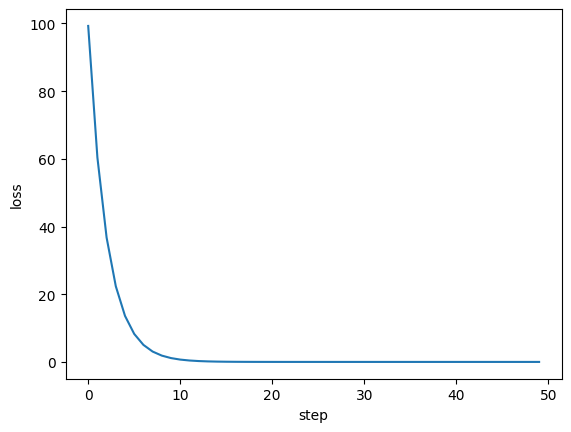

In [ ]:
from matplotlib import pyplot as plt

x = torch.tensor([1., 2., 3., 4., 5.])
y = torch.tensor([3.1, 5.9, 9.2, 11.8, 15.1])

# The variable requires_grad states whether you wish to track this for gradients or not
w = torch.tensor(0.0, requires_grad=True)

# The learning rate = step size
lr = 0.01
losses = []
# We repeat the training step 50 times
for step in range(50):
  prediction = w * x

  # This loss function is called the Mean Squared Error (MSE), because it takes the mean of (prediction - y) squared
  loss = ((prediction - y)**2).mean()

  # We need to compute the gradients by means of backpropagation
  loss.backward()

  # with torch.no_grad(): do not record operations in this block for calculating the gradients
  # We only want to trace steps towards the prediction for computing the gradients
  # The following lines update/change the parameters based on the calcualted gradients in the backward step (optimization)
  with torch.no_grad():
      w -= lr * w.grad
      w.grad.zero_()

  # Your code here to store the loss.item() in the losses
  losses.append(loss.item())

print(w)
print(losses)
plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss")


We can perform the same steps with the optmizer already provided by PyTorch.

👋 ⚒ Exercise 6: Change the learning rate in the following code cell to 0.1. What happens?

tensor(-27331.4609, requires_grad=True)


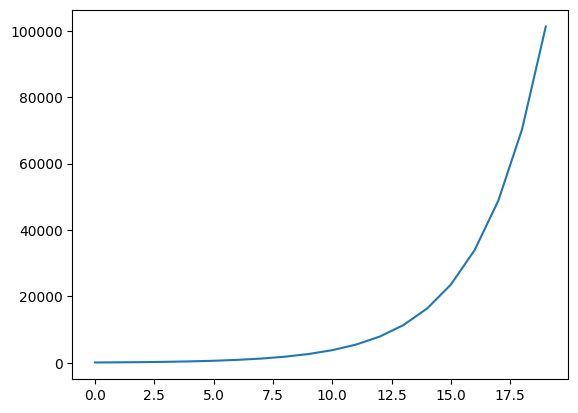

In [ ]:
w = torch.tensor(0.0, requires_grad=True)

# SGD means Stochastic Gradient Descent
optim = torch.optim.SGD([w], lr=0.1)
losses = []
for step in range(50):
    loss = ((w * x - y) ** 2).mean()
    optim.zero_grad()      # forget old gradients
    loss.backward()      # compute new gradients
    optim.step()           # update parameters
    losses.append(loss.item())
plt.plot(losses[:20]); print(w)